In [239]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/checking-logs.sqlite")

In [240]:
cheks = pd.io.sql.read_sql(
"SELECT * FROM checker where uid not like 'admin_%' ", conn)
cheks.head()

,index,status,success,timestamp,numTrials,labname,uid
0,7,ready,0,2020-04-17 05:19:02.744528,1,project1,user_4
1,8,checking,0,2020-04-17 05:22:35.249331,2,project1,user_4
2,9,ready,1,2020-04-17 05:22:45.549397,2,project1,user_4
3,10,checking,1,2020-04-17 05:34:14.691200,3,project1,user_4
4,11,ready,1,2020-04-17 05:34:24.422370,3,project1,user_4


In [241]:
ch = pd.io.sql.read_sql(
"""
--sql
SELECT count(*) AS commits, date(timestamp) AS date,
CASE 
    WHEN strftime('%H', timestamp) < '04' THEN 'night'
    WHEN strftime('%H', timestamp) < '10' THEN 'morning'
    WHEN strftime('%H', timestamp) < '17' THEN 'afternoon'
    ELSE 'evening' END AS daytime
FROM checker 
WHERE uid NOT LIKE 'admin_%' 
GROUP BY date, daytime""", conn)
display(ch.nlargest(5, 'commits'))

,commits,date,daytime
70,291,2020-05-14,afternoon
71,277,2020-05-14,evening
65,215,2020-05-12,evening
39,200,2020-05-02,afternoon
25,165,2020-04-26,evening


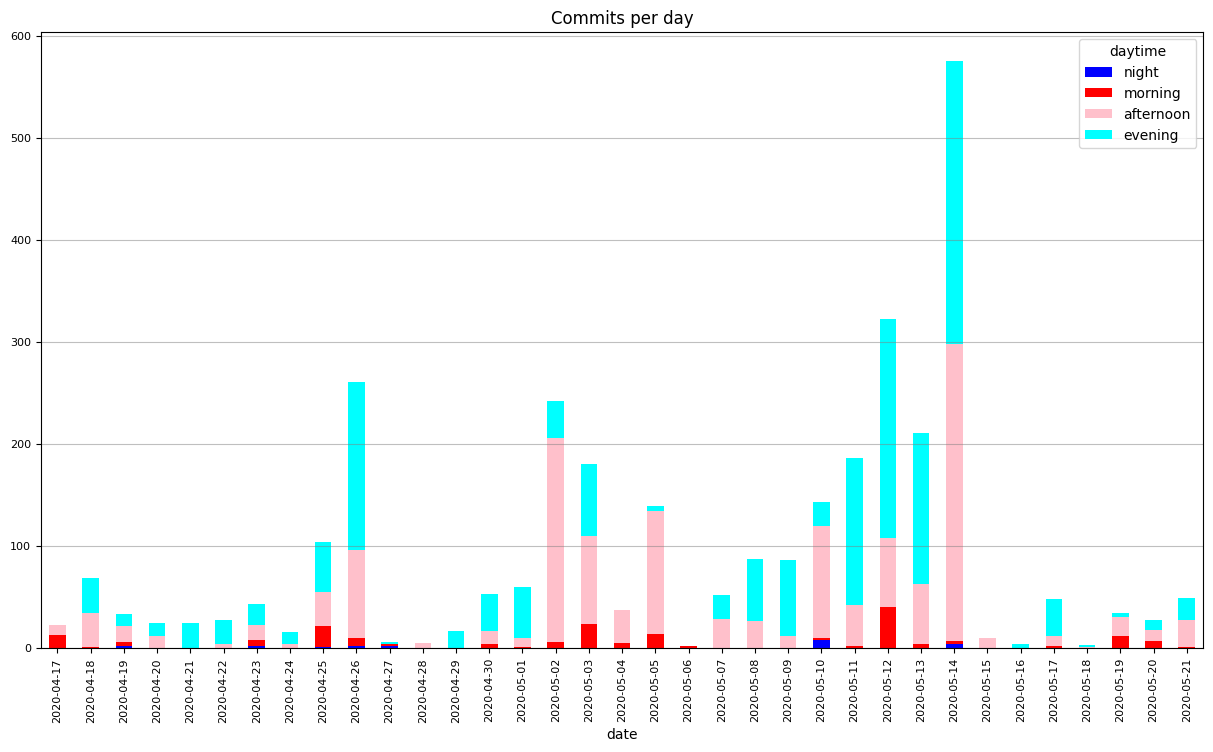

In [242]:
ch_pvt = ch.pivot(index='date', columns='daytime', values='commits')
order = ['night', 'morning', 'afternoon', 'evening']
ch_pvt = ch_pvt[order]

pl = ch_pvt.plot(
    kind='bar',
    stacked=True,
    title='Commits per day',
    figsize=(15, 8),
    fontsize=8,
    color=['blue', 'red', 'pink', 'cyan'] 
)
pl.grid(axis='y', color='gray', alpha=0.5)

In [243]:
# ch_pvt.info()
ch_pvt.shape

(35, 4)

In [ ]:
# ch_pvt.head()

daytime,night,morning,afternoon,evening
date,,,,
2020-04-17,NaN,13.0,10.0,NaN
2020-04-18,NaN,1.0,33.0,35.0
2020-04-19,2.0,4.0,16.0,11.0
2020-04-20,NaN,NaN,12.0,13.0
2020-04-21,NaN,NaN,NaN,25.0


In [ ]:
# ch_pvt.sum()

daytime
night          21.0
morning       184.0
afternoon    1391.0
evening      1611.0
dtype: float64

In [246]:
ch_pvt.sum().sort_values(ascending=False).head(2)

daytime
evening      1611.0
afternoon    1391.0
dtype: float64

## Когда наши пользователи обычно коммитят: ночью, утром, днём или вечером?

**Ответ:** днём и вечером.

In [247]:
filter_days = ch_pvt[ch_pvt['evening'] > ch_pvt['afternoon']]
total= filter_days.sum(axis=1)
total.idxmax()

'2020-05-12'

## Какой день имел максимальное число коммитов и при этом вечером коммитов больше, чем днём?

**Ответ:** 2020-05-14

In [248]:
conn.close()